# Chest X-Ray Multi-Label Classification —
\

**Data:** NIH ChestX-ray14 subset (512 px) · 13 diseases + *No Finding* · *Hernia* excluded (too few images)

The architecture is **identical in all three runs** (Input → normalization → DenseNet121 → GAP → Dropout → Dense sigmoid). Only the training setup changes:

| Run | Setup | Backbone |
|---|---|---|
| **Run 1 – Baseline** | `[-1, 1]` scaling, plain BCE, small shuffle buffer, checkpoint on `val_loss` | frozen |
| **Run 2 – Fixed** | ImageNet mean/std normalization, class-weighted BCE, full shuffle, light augmentation, checkpoint on `val_macro_auc` | frozen |
| **Run 3 – Fine-tuned** | Run 2 + the whole DenseNet121 trained with a small learning rate | trainable |


## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%pip install -q mlflow

In [ ]:
import os, json, random, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import mlflow
from IPython.display import display
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                             recall_score, precision_recall_curve)

# ---------------- Config ----------------
PROJECT_DIR = Path("/content/drive/MyDrive/x_ray_ds")   # zips, csv files, models, mlflow.db
DATA_ROOT   = Path("/content/chest_xray_512_merged")    # extracted "archive (1).zip"
EXTRA_DIR   = Path("/content/images_5_6")               # extracted "images_5_6.zip"
MODEL_DIR   = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

EXCLUDED_CLASSES = {"Hernia"}
IMG_SIZE   = 224
BATCH_SIZE = 32
EPOCHS_FROZEN   = 6      # Run 2
EPOCHS_FINETUNE = 12     # Run 3 (early stopping usually ends it sooner)
RUN_BASELINE    = False  # Run 1 is already in mlflow.db; set True to retrain it

RUN1_PATH   = MODEL_DIR / "run1_baseline.keras"
RUN2_PATH   = MODEL_DIR / "run2_fixed_frozen.keras"
RUN3_PATH   = MODEL_DIR / "run3_finetuned.keras"
CONFIG_PATH = MODEL_DIR / "inference_config.json"

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "NOT FOUND - switch the runtime to a GPU")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Extract the data
Skipped automatically if the folders already exist in this session.

In [ ]:
def extract_once(zip_path, dest, check_path):
    if check_path.exists():
        print(f"Already extracted: {check_path}")
        return
    print(f"Extracting {zip_path.name} ... (takes a few minutes)")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(dest)
    print("Done.")

extract_once(PROJECT_DIR / "archive (1).zip", Path("/content"), DATA_ROOT)
extract_once(PROJECT_DIR / "images_5_6.zip", EXTRA_DIR, EXTRA_DIR)

# file name -> full path, for every image on disk (train, augmented, extra, val, test)
IMG_EXT = {".png", ".jpg", ".jpeg"}
image_index = {
    p.name: str(p)
    for root in (DATA_ROOT, EXTRA_DIR)
    for p in root.rglob("*")
    if p.suffix.lower() in IMG_EXT
}
print("Images found on disk:", len(image_index))

Extracting archive (1).zip ... (takes a few minutes)
Done.
Extracting images_5_6.zip ... (takes a few minutes)
Done.
Images found on disk: 37545


## 3. Train / validation / test tables
- **Train** = `combined.csv` (original train + offline-augmented images + the extra `images_5_6` images)
- **Validation / Test** = the dataset's own splits
- *Hernia* is removed from every label list; images whose **only** label was Hernia are dropped (otherwise they would look like empty / healthy images)
- Patient-level leakage check: no patient may appear in train and in validation/test

In [ ]:
def clean_labels(s):
    if pd.isna(s):
        return []
    return [l.strip() for l in str(s).split("|")
            if l.strip() and l.strip() not in EXCLUDED_CLASSES]

def patient_from_name(name):
    # "00000248_019.png" and "00000248_019_aug_Mass_1.png" both belong to patient 248
    head = str(name).split("_")[0]
    return int(head) if head.isdigit() else -1

def prepare(df, name):
    df = df.copy()
    df["Image Index"] = df["Image Index"].astype(str).str.strip()
    df = df.drop_duplicates("Image Index")
    df["image_path"]  = df["Image Index"].map(image_index)
    df["patient"]     = df["Image Index"].map(patient_from_name)
    df["labels_list"] = df["Finding Labels"].apply(clean_labels)

    no_image = int(df["image_path"].isna().sum())
    no_label = int((df["labels_list"].str.len() == 0).sum())
    df = df[df["image_path"].notna() & (df["labels_list"].str.len() > 0)].reset_index(drop=True)
    print(f"{name:<10} {len(df):>6} images | missing on disk: {no_image} | dropped (Hernia only): {no_label}")
    return df[["Image Index", "Finding Labels", "patient", "image_path", "labels_list"]]

train_df = prepare(pd.read_csv(PROJECT_DIR / "combined.csv"), "train")
val_df   = prepare(pd.read_csv(DATA_ROOT / "validation" / "validation.csv"), "validation")
test_df  = prepare(pd.read_csv(DATA_ROOT / "test" / "test.csv"), "test")

# Patient-level leakage
held_out = (set(val_df["patient"]) | set(test_df["patient"])) - {-1}
leak = train_df["patient"].isin(held_out)
train_df = train_df[~leak].reset_index(drop=True)
print("\nTrain images from val/test patients (removed):", int(leak.sum()))
print("Patients shared by val and test:", len((set(val_df["patient"]) & set(test_df["patient"])) - {-1}))
print("Final train size:", len(train_df))

train       26530 images | missing on disk: 0 | dropped (Hernia only): 0
validation   5646 images | missing on disk: 0 | dropped (Hernia only): 0
test         5369 images | missing on disk: 0 | dropped (Hernia only): 0

Train images from val/test patients (removed): 0
Patients shared by val and test: 0
Final train size: 26530


## 4. Labels and class distribution
*No Finding* is about 19% of train but over half of validation/test. That shift makes `val_loss` a poor guide, so checkpoints and early stopping follow **validation macro AUC**, which does not depend on class frequency.

14 classes: ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Infiltration', 'Mass', 'No Finding', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']


,train,val,test,train %,val %,test %
Infiltration,7834,862,755,29.5,15.3,14.1
No Finding,5000,3148,3224,18.8,55.8,60.0
Atelectasis,4942,531,506,18.6,9.4,9.4
Effusion,4504,597,506,17.0,10.6,9.4
Mass,2767,220,196,10.4,3.9,3.7
Nodule,2529,272,282,9.5,4.8,5.3
Consolidation,2528,198,189,9.5,3.5,3.5
Pneumothorax,1988,340,181,7.5,6.0,3.4
Pleural_Thickening,1907,185,153,7.2,3.3,2.8
Cardiomegaly,1384,241,130,5.2,4.3,2.4


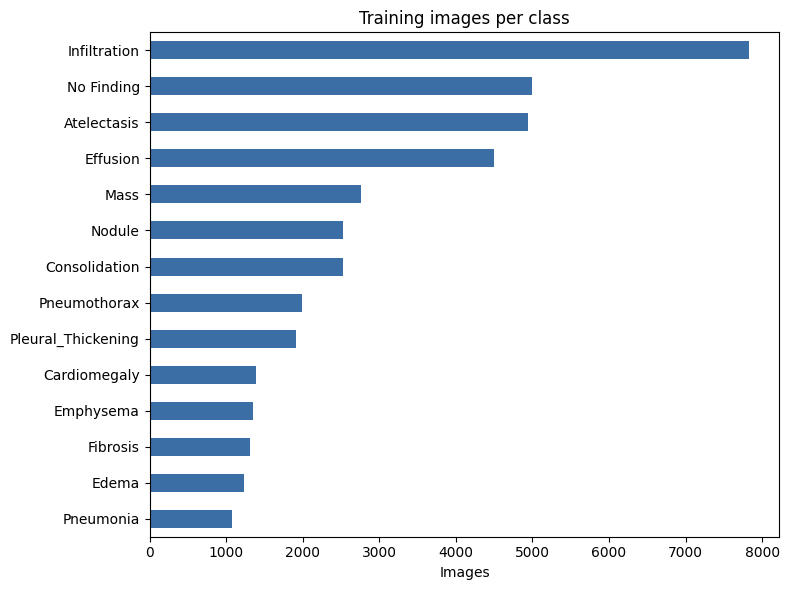

In [ ]:
mlb = MultiLabelBinarizer()
y_train = mlb.fit_transform(train_df["labels_list"]).astype("float32")
y_val   = mlb.transform(val_df["labels_list"]).astype("float32")
y_test  = mlb.transform(test_df["labels_list"]).astype("float32")
classes = list(mlb.classes_)
NUM_CLASSES = len(classes)
print(NUM_CLASSES, "classes:", classes)

dist = pd.DataFrame({"train": y_train.sum(0), "val": y_val.sum(0), "test": y_test.sum(0)},
                    index=classes).astype(int)
for split, n in [("train", len(train_df)), ("val", len(val_df)), ("test", len(test_df))]:
    dist[f"{split} %"] = (100 * dist[split] / n).round(1)
display(dist.sort_values("train", ascending=False))

ax = dist["train"].sort_values().plot.barh(figsize=(8, 6), color="#3b6ea5")
ax.set_title("Training images per class"); ax.set_xlabel("Images")
plt.tight_layout(); plt.show()

## 5. Input pipeline
- **Full shuffle** every epoch (the files are ordered by patient, and the extra images sit at the end)
- **Light augmentation** on train only: small rotation / zoom / shift + brightness / contrast. No flips, because chest X-rays have a fixed orientation.
- Pixels are fed in `[0, 1]`; ImageNet normalization happens **inside the model**, so the deployed app only resizes and divides by 255.

Batch: (32, 224, 224, 3) (32, 14) | pixel range: 0.0 - 1.0


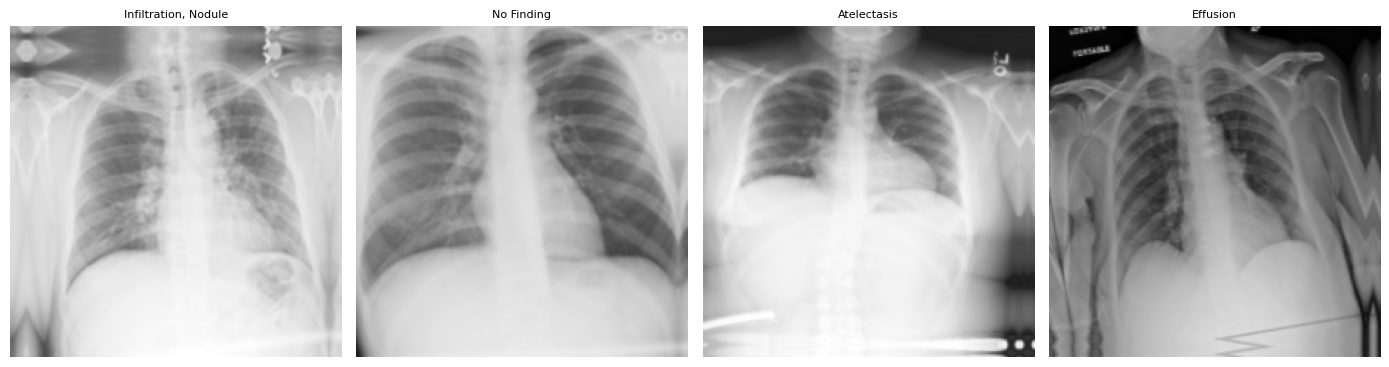

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE]) / 255.0
    return img, label

def color_aug(img, label):
    img = tf.image.random_brightness(img, 0.1)
    img = tf.image.random_contrast(img, 0.9, 1.1)
    return tf.clip_by_value(img, 0.0, 1.0), label

geo_aug = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),            # about +/- 10 degrees
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
], name="geo_aug")

def make_ds(df, labels, training, augment=True, shuffle_buffer=None):
    ds = tf.data.Dataset.from_tensor_slices((df["image_path"].values, labels))
    if training:
        ds = ds.shuffle(shuffle_buffer or len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training and augment:
        ds = ds.map(color_aug, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    if training and augment:
        ds = ds.map(lambda x, l: (geo_aug(x, training=True), l), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, y_train, training=True)
val_ds   = make_ds(val_df, y_val, training=False)
test_ds  = make_ds(test_df, y_test, training=False)

# Sanity check + preview of augmented training images
imgs, labs = next(iter(train_ds))
print("Batch:", imgs.shape, labs.shape,
      "| pixel range:", round(float(tf.reduce_min(imgs)), 3), "-", round(float(tf.reduce_max(imgs)), 3))
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, img, lab in zip(axes, imgs[:4], labs[:4]):
    ax.imshow(img.numpy()); ax.axis("off")
    ax.set_title(", ".join(c for c, v in zip(classes, lab.numpy()) if v), fontsize=8)
plt.tight_layout(); plt.show()

## 6. Model, loss and MLflow helpers
- `build_model()` is the same architecture for every run.
- **Weighted BCE** gives positive examples of rare classes more weight (`pos_weight = negatives / positives`, capped at 20). The original notebook computed these weights but never used them.

In [ ]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import DenseNet121

def build_model(normalization="imagenet"):
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="xray_image")
    if normalization == "imagenet":
        # Correct preprocessing for Keras DenseNet121: ImageNet mean / std
        x = layers.Normalization(mean=[0.485, 0.456, 0.406],
                                 variance=[0.229 ** 2, 0.224 ** 2, 0.225 ** 2],
                                 name="imagenet_norm")(inputs)
    else:
        # Original baseline preprocessing ([-1, 1]); only used to reproduce Run 1
        x = layers.Rescaling(2.0, offset=-1.0, name="minus1_to_1")(inputs)
    base = DenseNet121(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="sigmoid", name="disease_probabilities")(x)
    return Model(inputs, outputs, name="xray_densenet121"), base

# ---- Class-weighted binary cross-entropy ----
pos_counts = y_train.sum(axis=0)
pos_weight = np.clip((len(y_train) - pos_counts) / np.maximum(pos_counts, 1), 1.0, 20.0)
POS_WEIGHT = tf.constant(pos_weight, dtype=tf.float32)
display(pd.Series(pos_weight.round(2), index=classes, name="pos_weight").sort_values().to_frame())

def weighted_bce(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    loss = -(POS_WEIGHT * y_true * tf.math.log(y_pred)
             + (1.0 - y_true) * tf.math.log(1.0 - y_pred))
    return tf.reduce_mean(loss, axis=-1)

# ---- MLflow (database on Drive) ----
mlflow.set_tracking_uri(f"sqlite:///{PROJECT_DIR / 'mlflow.db'}")
mlflow.set_experiment("Chest_XRay_MultiLabel")

class MLflowMetricsCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        for k, v in (logs or {}).items():
            try:
                mlflow.log_metric(k, float(v), step=epoch + 1)
            except (TypeError, ValueError):
                pass

def train_run(run_name, model, lr, loss, train_data, epochs, ckpt_path, params,
              monitor="val_macro_auc", use_schedulers=True):
    mode = "max" if "auc" in monitor else "min"
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=loss,
        metrics=[tf.keras.metrics.AUC(multi_label=True, num_labels=NUM_CLASSES, name="macro_auc")],
    )
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(str(ckpt_path), monitor=monitor, mode=mode,
                                           save_best_only=True, verbose=1),
        MLflowMetricsCallback(),
    ]
    if use_schedulers:
        callbacks += [
            tf.keras.callbacks.ReduceLROnPlateau(monitor=monitor, mode=mode, factor=0.3,
                                                 patience=1, min_lr=1e-6, verbose=1),
            tf.keras.callbacks.EarlyStopping(monitor=monitor, mode=mode, patience=3,
                                             restore_best_weights=True, verbose=1),
        ]
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.log_params({**params,
                           "learning_rate": lr, "max_epochs": epochs, "image_size": IMG_SIZE,
                           "batch_size": BATCH_SIZE, "num_classes": NUM_CLASSES,
                           "train_images": len(train_df), "checkpoint_monitor": monitor,
                           "model_file": Path(ckpt_path).name})
        history = model.fit(train_data, validation_data=val_ds, epochs=epochs, callbacks=callbacks)
        best_auc = float(max(history.history["val_macro_auc"]))
        mlflow.log_metric("best_val_macro_auc", best_auc)
        print(f"\n{run_name}: best validation macro AUC = {best_auc:.4f}")
        return run.info.run_id, history

def plot_history(history, title):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title("Loss")
    axes[1].plot(h["macro_auc"], label="train"); axes[1].plot(h["val_macro_auc"], label="validation")
    axes[1].set_title("Macro AUC")
    for ax in axes:
        ax.set_xlabel("Epoch"); ax.legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()

,pos_weight
Infiltration,2.39
No Finding,4.31
Atelectasis,4.37
Effusion,4.89
Mass,8.59
Nodule,9.49
Consolidation,9.49
Pneumothorax,12.35
Pleural_Thickening,12.91
Cardiomegaly,18.17


## 7. Run 1 — Baseline
Already logged in `mlflow.db` (validation macro AUC ≈ 0.69). Set `RUN_BASELINE = True` in the config cell to train it again.

In [ ]:
if RUN_BASELINE:
    tf.keras.backend.clear_session()
    baseline_train_ds = make_ds(train_df, y_train, training=True, augment=False, shuffle_buffer=2000)
    model, _ = build_model(normalization="minus1_1")
    run1_id, history = train_run(
        "Run1_baseline", model, lr=1e-3, loss=tf.keras.losses.BinaryCrossentropy(),
        train_data=baseline_train_ds, epochs=10, ckpt_path=RUN1_PATH,
        params={"model": "DenseNet121", "backbone": "frozen", "normalization": "minus1_to_1",
                "loss": "BCE", "augmentation": "none", "shuffle_buffer": 2000},
        monitor="val_loss", use_schedulers=False)
    plot_history(history, "Run 1 - Baseline")
else:
    print("Skipped: Run 1 (DenseNet121_baseline) is already logged in mlflow.db")

Skipped: Run 1 (DenseNet121_baseline) is already logged in mlflow.db


## 8. Run 2 — Fixed pipeline, frozen backbone
Same architecture as Run 1, with every training fix applied. The backbone stays frozen so this run isolates the effect of the fixes.

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/6
830/830 ━━━━━━━━━━━━━━━━━━━━ 0s 538ms/step - loss: 1.3188 - macro_auc: 0.5724
Epoch 1: val_macro_auc improved from None to 0.69153, saving model to /content/drive/MyDrive/x_ray_ds/models/run2_fixed_frozen.keras

Epoch 1: finished saving model to /content/drive/MyDrive/x_ray_ds/models/run2_fixed_frozen.keras
830/830 ━━━━━━━━━━━━━━━━━━━━ 532s 605ms/step - loss: 1.2521 - macro_auc: 0.6106 - val_loss: 0.9383 - val_macro_auc: 0.6915 - learning_rate: 0.0010
Epoch 2/6
829/830 ━━━━━━━━━━━━━━━━━━━━ 0s 503ms/step - loss: 1.1698 - macro_auc: 0.6599
Epoch 2: val_macro_auc improved from 0.69153 to 0.69989, saving model to /content/drive/MyDrive/x_ray_ds/models/run2_fixed_frozen.keras

Epoch 2: finished saving model to /content/drive/MyDrive/x_ray_ds/models/run2_fixed_frozen.keras
830/830 ━━━━━━━━━━━━━━━━━━━━ 502s 555ms/step - loss: 1.1599 - macro_auc: 0.6657 - val_loss: 0.9252 - val_macro_auc: 0.6999 - learning_rate: 0.0010
Epoch 3/6
829/

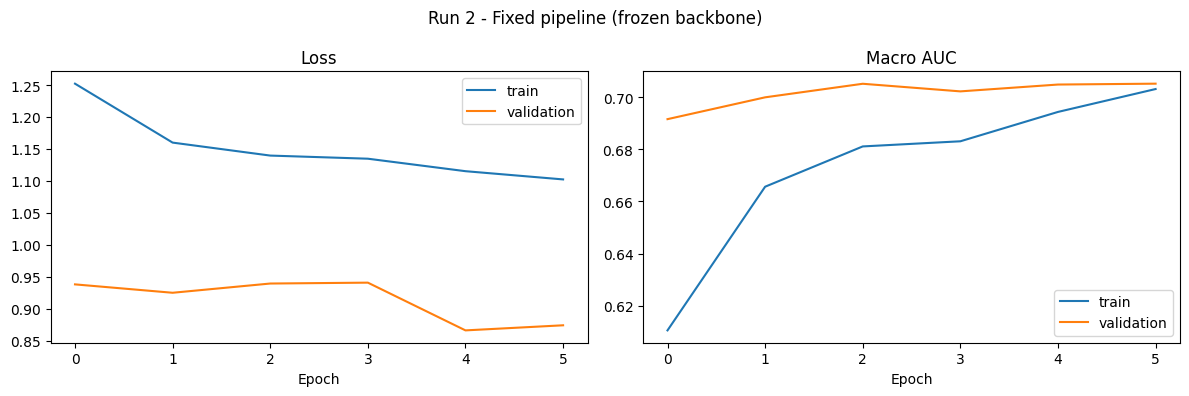

In [ ]:
tf.keras.backend.clear_session()
model, base = build_model(normalization="imagenet")

run2_id, history = train_run(
    "Run2_fixed_frozen", model, lr=1e-3, loss=weighted_bce,
    train_data=train_ds, epochs=EPOCHS_FROZEN, ckpt_path=RUN2_PATH,
    params={"model": "DenseNet121", "backbone": "frozen", "normalization": "imagenet_mean_std",
            "loss": "weighted_bce", "augmentation": "rotate/zoom/shift/brightness/contrast",
            "shuffle_buffer": "full"})
plot_history(history, "Run 2 - Fixed pipeline (frozen backbone)")

## 9. Run 3 — Fine-tune the whole DenseNet121
Starts from the best Run 2 checkpoint, unfreezes the DenseNet121 weights and trains with a 10× smaller learning rate so the pretrained features adapt to X-rays without being destroyed. BatchNorm layers stay frozen, which keeps fine-tuning stable. This is the longest run.

Trainable parameters: 6,884,558
Epoch 1/12
830/830 ━━━━━━━━━━━━━━━━━━━━ 0s 577ms/step - loss: 1.1861 - macro_auc: 0.6236
Epoch 1: val_macro_auc improved from None to 0.72137, saving model to /content/drive/MyDrive/x_ray_ds/models/run3_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/x_ray_ds/models/run3_finetuned.keras
830/830 ━━━━━━━━━━━━━━━━━━━━ 615s 642ms/step - loss: 1.1385 - macro_auc: 0.6688 - val_loss: 0.8879 - val_macro_auc: 0.7214 - learning_rate: 1.0000e-04
Epoch 2/12
830/830 ━━━━━━━━━━━━━━━━━━━━ 0s 522ms/step - loss: 1.0644 - macro_auc: 0.7271
Epoch 2: val_macro_auc improved from 0.72137 to 0.75197, saving model to /content/drive/MyDrive/x_ray_ds/models/run3_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/x_ray_ds/models/run3_finetuned.keras
830/830 ━━━━━━━━━━━━━━━━━━━━ 477s 574ms/step - loss: 1.0498 - macro_auc: 0.7342 - val_loss: 0.8495 - val_macro_auc: 0.7520 - learning_rate: 1.0000e-04
Epoch 3/12
829/830 ━━━━━━━━━━━━━━━━

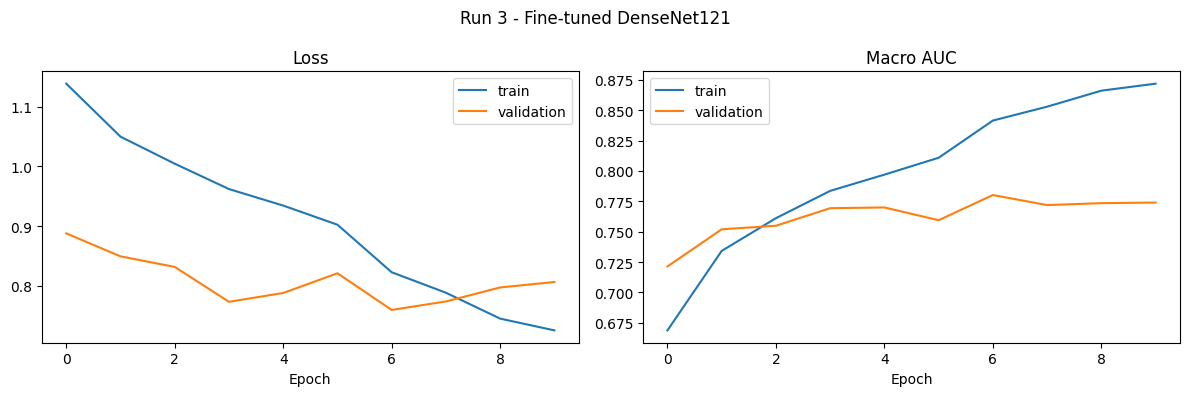

In [ ]:
tf.keras.backend.clear_session()
model = tf.keras.models.load_model(RUN2_PATH, compile=False)            # best Run 2 weights
base = next(l for l in model.layers if isinstance(l, tf.keras.Model))   # the DenseNet121 block
base.trainable = True
for layer in base.layers:   # keep BatchNorm frozen (inference mode) - standard for fine-tuning
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
print(f"Trainable parameters: {sum(int(np.prod(w.shape)) for w in model.trainable_weights):,}")

run3_id, history = train_run(
    "Run3_finetune_full", model, lr=1e-4, loss=weighted_bce,
    train_data=train_ds, epochs=EPOCHS_FINETUNE, ckpt_path=RUN3_PATH,
    params={"model": "DenseNet121", "backbone": "trainable", "normalization": "imagenet_mean_std",
            "loss": "weighted_bce", "augmentation": "rotate/zoom/shift/brightness/contrast",
            "shuffle_buffer": "full", "init_weights": "Run2 best checkpoint"})
plot_history(history, "Run 3 - Fine-tuned DenseNet121")

## 10. Final evaluation on the test set
1. For each disease, pick the probability threshold that maximizes F1 **on validation**.
2. Report AUC / F1 / precision / recall on the **test set**, which was never used for training or tuning.
3. Save classes + thresholds to `inference_config.json` for the Streamlit app.

177/177 ━━━━━━━━━━━━━━━━━━━━ 56s 242ms/step
168/168 ━━━━━━━━━━━━━━━━━━━━ 45s 265ms/step
TEST SET - macro averages


,threshold 0.5,tuned thresholds
AUC,0.7661,0.7661
F1,0.2518,0.2832
Precision,0.1824,0.2339
Recall,0.5382,0.3769


,Disease,AUC,F1,Precision,Recall,Threshold,Positives
0,Atelectasis,0.775,0.358,0.278,0.504,0.641,506
1,Cardiomegaly,0.931,0.427,0.341,0.569,0.891,130
2,Consolidation,0.739,0.121,0.083,0.228,0.638,189
3,Edema,0.810,0.107,0.075,0.189,0.862,74
4,Effusion,0.854,0.446,0.392,0.518,0.685,506
5,Emphysema,0.875,0.353,0.299,0.432,0.847,95
6,Fibrosis,0.707,0.125,0.128,0.122,0.711,131
7,Infiltration,0.716,0.362,0.286,0.494,0.540,755
8,Mass,0.729,0.176,0.164,0.189,0.679,196
9,No Finding,0.742,0.765,0.689,0.860,0.372,3224


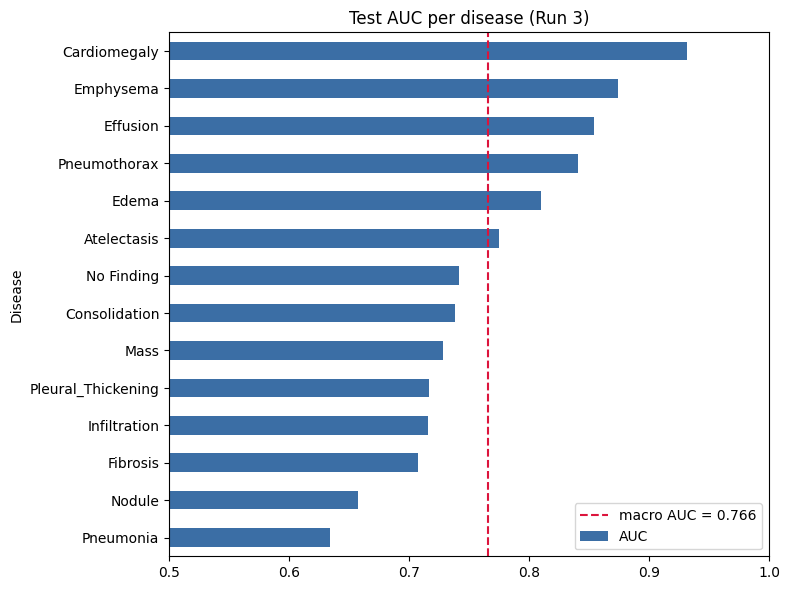

Saved: /content/drive/MyDrive/x_ray_ds/models/inference_config.json


In [ ]:
tf.keras.backend.clear_session()
final_model = tf.keras.models.load_model(RUN3_PATH, compile=False)

val_prob  = final_model.predict(val_ds, verbose=1)
test_prob = final_model.predict(test_ds, verbose=1)

# 1) Per-class threshold that maximizes F1 on validation
thresholds = np.zeros(NUM_CLASSES)
for i in range(NUM_CLASSES):
    p, r, t = precision_recall_curve(y_val[:, i], val_prob[:, i])
    f1 = 2 * p * r / (p + r + 1e-8)
    thresholds[i] = t[np.argmax(f1[:-1])]

# 2) Test-set metrics
def per_class_metrics(y_true, prob, th):
    th = np.broadcast_to(th, (NUM_CLASSES,))
    pred = (prob >= th).astype(int)
    rows = []
    for i, c in enumerate(classes):
        has_both = len(np.unique(y_true[:, i])) == 2
        rows.append({
            "Disease": c,
            "AUC": roc_auc_score(y_true[:, i], prob[:, i]) if has_both else np.nan,
            "F1": f1_score(y_true[:, i], pred[:, i], zero_division=0),
            "Precision": precision_score(y_true[:, i], pred[:, i], zero_division=0),
            "Recall": recall_score(y_true[:, i], pred[:, i], zero_division=0),
            "Threshold": float(th[i]),
            "Positives": int(y_true[:, i].sum()),
        })
    return pd.DataFrame(rows)

test_05    = per_class_metrics(y_test, test_prob, 0.5)
test_tuned = per_class_metrics(y_test, test_prob, thresholds)

summary = pd.DataFrame({
    "threshold 0.5":    test_05[["AUC", "F1", "Precision", "Recall"]].mean(),
    "tuned thresholds": test_tuned[["AUC", "F1", "Precision", "Recall"]].mean(),
}).round(4)
print("TEST SET - macro averages")
display(summary)
display(test_tuned.round(3))

ax = test_tuned.set_index("Disease")["AUC"].sort_values().plot.barh(figsize=(8, 6), color="#3b6ea5")
ax.axvline(test_tuned["AUC"].mean(), color="crimson", ls="--",
           label=f"macro AUC = {test_tuned['AUC'].mean():.3f}")
ax.set_xlim(0.5, 1.0); ax.set_title("Test AUC per disease (Run 3)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

# 3) Save what the Streamlit app needs + log test metrics into Run 3
config = {
    "model_file": RUN3_PATH.name,
    "img_size": IMG_SIZE,
    "input": "RGB, resized to img_size, pixel values / 255 (normalization is inside the model)",
    "classes": classes,
    "thresholds": [float(t) for t in thresholds],
}
with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=2)
test_tuned.to_csv(MODEL_DIR / "run3_test_metrics.csv", index=False)

run3 = mlflow.search_runs(filter_string="tags.mlflow.runName = 'Run3_finetune_full'",
                          order_by=["attributes.start_time DESC"], max_results=1)
with mlflow.start_run(run_id=run3.iloc[0]["run_id"]):
    mlflow.log_metrics({
        "test_macro_auc":       float(test_tuned["AUC"].mean()),
        "test_macro_f1_tuned":  float(test_tuned["F1"].mean()),
        "test_macro_f1_at_05":  float(test_05["F1"].mean()),
    })
print("Saved:", CONFIG_PATH)

## 11. Compare the three runs
Same numbers you will see in the MLflow UI, as one table for the report.

In [ ]:
runs = mlflow.search_runs(order_by=["attributes.start_time ASC"])
runs = runs[runs["status"] == "FINISHED"]
keep = ["DenseNet121_baseline", "Run1_baseline", "Run2_fixed_frozen", "Run3_finetune_full"]
runs = runs[runs["tags.mlflow.runName"].isin(keep)].drop_duplicates("tags.mlflow.runName", keep="last")

cols = {
    "tags.mlflow.runName": "Run",
    "params.backbone": "Backbone",
    "params.normalization": "Normalization",
    "params.loss": "Loss",
    "params.learning_rate": "LR",
    "metrics.best_val_macro_auc": "Best val AUC",
    "metrics.val_macro_auc": "Last-epoch val AUC",
    "metrics.test_macro_auc": "Test AUC",
    "metrics.test_macro_f1_tuned": "Test F1 (tuned)",
}
display(runs[[c for c in cols if c in runs.columns]].rename(columns=cols).reset_index(drop=True))

,Run,Backbone,Normalization,Loss,LR,Best val AUC,Last-epoch val AUC,Test AUC,Test F1 (tuned)
0,DenseNet121_baseline,None,None,BinaryCrossentropy,0.001,NaN,0.684916,NaN,NaN
1,Run2_fixed_frozen,frozen,imagenet_mean_std,weighted_bce,0.001,0.705120,0.705120,NaN,NaN
2,Run3_finetune_full,trainable,imagenet_mean_std,weighted_bce,0.0001,0.780183,0.773980,0.766103,0.283207


## 12. Quick inference check
Exactly the steps the Streamlit app will use: load the image → resize → divide by 255 → predict → compare with each class threshold.

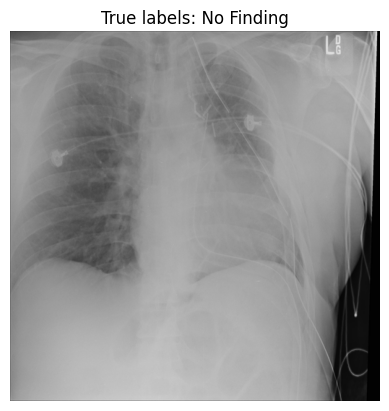

,Disease,Probability,Threshold,Detected
0,Emphysema,0.708,0.847,False
1,Infiltration,0.626,0.540,True
2,Edema,0.558,0.862,False
3,Pneumothorax,0.539,0.677,False
4,No Finding,0.473,0.372,True
5,Consolidation,0.446,0.638,False
6,Nodule,0.397,0.665,False
7,Mass,0.322,0.679,False
8,Atelectasis,0.282,0.641,False
9,Pneumonia,0.228,0.666,False


In [ ]:
def predict_image(path, model, config):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [config["img_size"], config["img_size"]]) / 255.0
    prob = model.predict(img[None, ...], verbose=0)[0]
    out = pd.DataFrame({"Disease": config["classes"], "Probability": prob,
                        "Threshold": config["thresholds"]})
    out["Detected"] = out["Probability"] >= out["Threshold"]
    return out.sort_values("Probability", ascending=False).reset_index(drop=True)

sample = test_df.sample(1, random_state=7).iloc[0]
plt.imshow(plt.imread(sample["image_path"]), cmap="gray"); plt.axis("off")
plt.title("True labels: " + ", ".join(sample["labels_list"])); plt.show()
display(predict_image(sample["image_path"], final_model, config).round(3))

## Outputs saved on Drive (`x_ray_ds/models/`)
| File | Use |
|---|---|
| `run3_finetuned.keras` | final model for deployment — load with `tf.keras.models.load_model(path, compile=False)` |
| `inference_config.json` | class order + per-class thresholds for the Streamlit app |
| `run2_fixed_frozen.keras` | Run 2 checkpoint |
| `run3_test_metrics.csv` | per-disease test results |

MLflow UI on your laptop (in the folder that has `mlflow.db`):
```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```